In [114]:
!pip install pygad

In [115]:
import imageio.v2 as imageio
import numpy
import gari
import matplotlib.pyplot

In [116]:
target_im = imageio.imread('fruit.jpg')
target_im = numpy.asarray(target_im / 255, dtype=float)

In [117]:
target_chromosome = gari.img2chromosome(target_im)

In [118]:
def fitness_fun(ga_instance, solution, solution_idx):
    fitness = numpy.sum(numpy.abs(target_chromosome-solution))

    # Negating the fitness value to make it increasing rather than decreasing.
    fitness = numpy.sum(target_chromosome) - fitness
    return fitness

In [119]:
import numpy
import functools
import operator

def img2chromosome(img_arr):
   return numpy.reshape(img_arr, (functools.reduce(operator.mul, img_arr.shape)))

def chromosome2img(vector, shape):
   if len(vector) != functools.reduce(operator.mul, shape):
       raise ValueError(f"A vector of length {len(vector)} into an array of shape {shape}.")

   return numpy.reshape(vector, shape)

In [120]:
import pygad

In [121]:
ga_instance = pygad.GA(num_generations=50000,
                       num_parents_mating=10,
                       fitness_func=fitness_fun,
                       sol_per_pop=20,
                       num_genes=target_im.size,
                       init_range_low=0.0,
                       init_range_high=1.0,
                       mutation_percent_genes=0.01,
                       mutation_type="random",
                       mutation_by_replacement=True,
                       random_mutation_min_val=0.0,
                       random_mutation_max_val=1.0)

In [122]:
ga_instance.run()

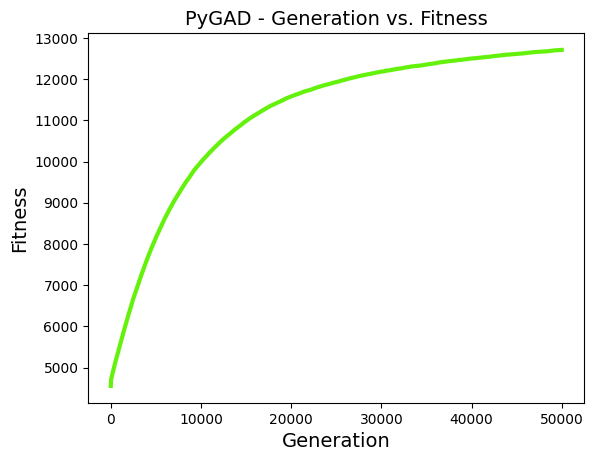

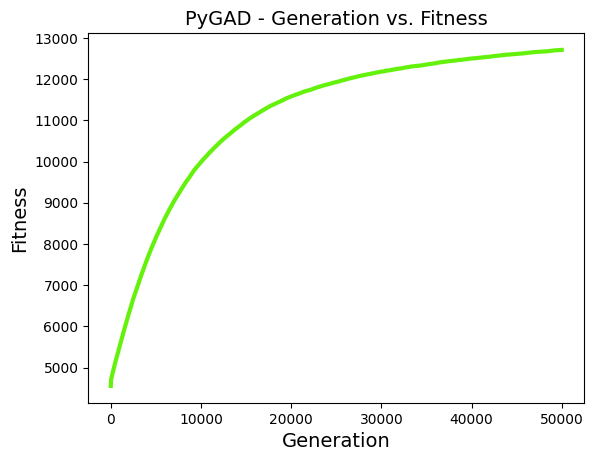

In [123]:
ga_instance.plot_fitness()

In [124]:
# Returning the details of the best solution.
solution, solution_fitness, solution_idx = ga_instance.best_solution()

print(f"Fitness value of the best solution = {solution_fitness}")
print(f"Index of the best solution : {solution_idx}")

if ga_instance.best_solution_generation != -1:
    print(f"Best fitness value reached after {ga_instance.best_solution_generation} generations.")

Fitness value of the best solution = 12707.325182785838
Index of the best solution : 0
Best fitness value reached after 49993 generations.


In [125]:
result = gari.chromosome2img(solution, target_im.shape)

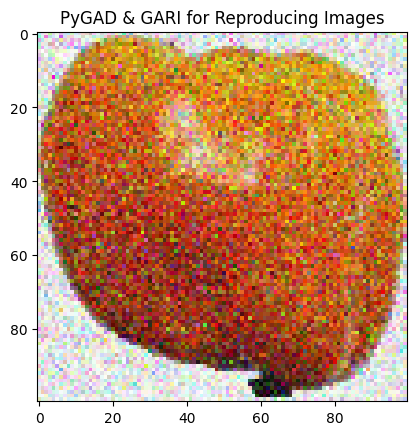

In [126]:
matplotlib.pyplot.imshow(result)
matplotlib.pyplot.title("PyGAD & GARI for Reproducing Images")
matplotlib.pyplot.show()